# NN_L5_load_errors

**Day-ahead Romanian hourly load, test days 2024-2026: MAPE of seasonal naive, naive, ridge ARX, RNN, LSTM and GRU (mean of 3 seeds), and MAE by hour.**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_load_errors/NN_L5_load_errors.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

24 hourly values of day d+1 forecast at the end of day d (UTC days).

MAPE seasonal naive (%) = 6.79   [load.snaive]
MAPE ridge ARX (%) = 4.86   [load.ridge]
MAPE rnn (%) = 5.29   [load.rnn.ens]
MAPE lstm (%) = 5.81   [load.lstm.ens]
MAPE gru (%) = 5.17   [load.gru.ens]
MAE LSTM (MW) = 331   [load.mae_lstm_mw]


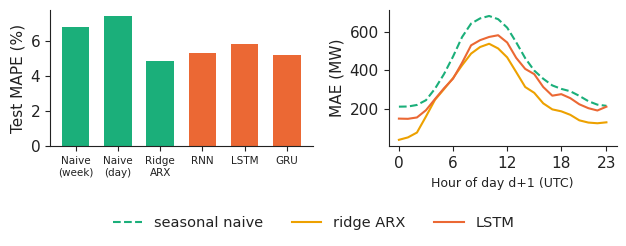

In [3]:
import json, urllib.request
_F = 'load_errors_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L5/NN_L5_load_errors/' + _F))
Y = np.array(R['y']); mape = lambda p: round(float(np.mean(np.abs(np.asarray(p) - Y) / Y) * 100), 2)
show('load.snaive', 'MAPE seasonal naive (%)', mape(R['nv'])); show('load.ridge', 'MAPE ridge ARX (%)', mape(R['ridge']))
for c in ['rnn', 'lstm', 'gru']: show(f'load.{c}.ens', f'MAPE {c} (%)', mape(R[c]))
show('load.mae_lstm_mw', 'MAE LSTM (MW)', int(round(float(np.mean(np.abs(np.array(R['lstm']) - Y))))))
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.5), gridspec_kw={'width_ratios': [1.15, 1]})
ks = ['nv', 'yd', 'ridge', 'rnn', 'lstm', 'gru']
axes[0].bar(range(6), [mape(R[k]) for k in ks], color=[PAL['benchmark']] * 3 + [PAL['model']] * 3, width=.65)
axes[0].set_xticks(range(6)); axes[0].set_xticklabels(['Naive\n(week)', 'Naive\n(day)', 'Ridge\nARX', 'RNN', 'LSTM', 'GRU'], fontsize=7.5); axes[0].set_ylabel('Test MAPE (%)')
for k, c, l, ls in [('nv', PAL['benchmark'], 'seasonal naive', '--'), ('ridge', PAL['alt'], 'ridge ARX', '-'), ('lstm', PAL['model'], 'LSTM', '-')]:
    axes[1].plot(range(24), np.mean(np.abs(np.array(R[k]) - Y), 0), color=c, ls=ls, lw=1.5, label=l)
axes[1].set_xlabel('Hour of day d+1 (UTC)', fontsize=9); axes[1].set_ylabel('MAE (MW)'); axes[1].set_xticks([0, 6, 12, 18, 23])
legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('load_errors.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()